In [1]:

from pathlib import Path
import sys
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == "ml":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.src.train_waste_model import *

print("Project root:", PROJECT_ROOT)
print("Food Waste notebook setup completed!")


Project root: d:\machine learning_project\WasteWise-AI\WasteWise-AI
Food Waste notebook setup completed!


In [2]:

from ml.src.train_waste_model import prepare_food_waste_data

# Prepare next-day food waste dataset
waste_df, numeric_features, categorical_features = prepare_food_waste_data()

print("Dataset shape:", waste_df.shape)
print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

print("\nWaste target summary:")
display(waste_df["target_waste_units"].describe().to_frame("value"))

print("\nFirst 10 rows:")
display(waste_df.head(10))


Dataset shape: (1790, 19)

Numeric features: ['opening_stock', 'units_received', 'units_sold', 'estimated_closing_stock', 'unit_price', 'discount_pct', 'days_to_expiry_next_day', 'temperature_c', 'stockout_flag', 'calendar_day_of_week', 'calendar_month', 'calendar_day_of_year_sin', 'calendar_day_of_year_cos', 'calendar_is_weekend']

Categorical features: ['product_id', 'category']

Waste target summary:


,value
count,1790.000000
mean,1.441341
std,5.980467
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,56.000000



First 10 rows:


,as_of_date,target_date,target_waste_units,opening_stock,units_received,units_sold,estimated_closing_stock,unit_price,discount_pct,days_to_expiry_next_day,temperature_c,stockout_flag,calendar_day_of_week,calendar_month,calendar_day_of_year_sin,calendar_day_of_year_cos,calendar_is_weekend,product_id,category
0,2026-04-01,2026-04-02,0.0,27,0,6,21,32.0,0.0,0,4.1,0,3.0,4.0,0.999930,-0.011826,0,1001,Dairy
1,2026-04-02,2026-04-03,0.0,30,12,5,37,32.0,0.0,4,3.7,0,4.0,4.0,0.999579,-0.029025,0,1001,Dairy
2,2026-04-03,2026-04-04,0.0,38,0,14,24,32.0,0.0,1,4.6,0,5.0,4.0,0.998932,-0.046215,1,1001,Dairy
3,2026-04-04,2026-04-05,0.0,49,0,11,38,32.0,0.0,-1,5.7,0,6.0,4.0,0.997989,-0.063391,1,1001,Dairy
4,2026-04-05,2026-04-06,0.0,19,13,12,20,32.0,0.0,-1,3.0,0,0.0,4.0,0.996751,-0.080549,0,1001,Dairy
5,2026-04-06,2026-04-07,0.0,27,0,13,14,32.0,0.0,0,4.1,0,1.0,4.0,0.995218,-0.097683,0,1001,Dairy
6,2026-04-07,2026-04-08,0.0,32,0,14,18,32.0,0.0,-1,6.2,0,2.0,4.0,0.993390,-0.114788,0,1001,Dairy
7,2026-04-08,2026-04-09,0.0,35,0,14,21,32.0,0.0,-1,5.1,0,3.0,4.0,0.991269,-0.131859,0,1001,Dairy
8,2026-04-09,2026-04-10,0.0,22,0,8,14,32.0,0.0,-1,2.6,0,4.0,4.0,0.988854,-0.148890,0,1001,Dairy
9,2026-04-10,2026-04-11,0.0,27,0,11,16,32.0,0.0,0,3.5,0,5.0,4.0,0.986146,-0.165878,1,1001,Dairy


In [3]:
#Train-Test Split

from ml.src.training_common import chronological_split

TARGET = "target_waste_units"

train_df, test_df, cutoff = chronological_split(
    waste_df, "target_date"
)

feature_columns = numeric_features + categorical_features

X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df[TARGET]
y_test = test_df[TARGET]

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Test cutoff:", cutoff)

print("\nWaste target statistics:")
print(y_train.describe())

print("\nNon-zero waste percentage in training data:")
print(f"{(y_train > 0).mean() * 100:.2f}%")


Training rows: 1430
Testing rows: 360
Test cutoff: 2026-08-23 00:00:00

Waste target statistics:
count    1430.000000
mean        1.384615
std         5.747818
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max        56.000000
Name: target_waste_units, dtype: float64

Non-zero waste percentage in training data:
7.20%


In [4]:
#Food Waste Model Training

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor

# Preprocess numerical features
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocess categorical features
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Create model
waste_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", ExtraTreesRegressor(
        n_estimators=250,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
waste_model.fit(X_train, y_train)

print("Food Waste Model trained successfully!")


Food Waste Model trained successfully!


In [5]:
#Model Evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

waste_predictions = waste_model.predict(X_test)

mae = mean_absolute_error(y_test, waste_predictions)
rmse = np.sqrt(mean_squared_error(y_test, waste_predictions))
r2 = r2_score(y_test, waste_predictions)

# Simple baseline: always predict zero waste
baseline_predictions = np.zeros(len(y_test))
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print("Food Waste Model Evaluation")
print("---------------------------")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")
print(f"Zero Baseline MAE: {baseline_mae:.3f}")

Food Waste Model Evaluation
---------------------------
MAE: 2.811
RMSE: 6.983
R2 Score: -0.048
Zero Baseline MAE: 1.667


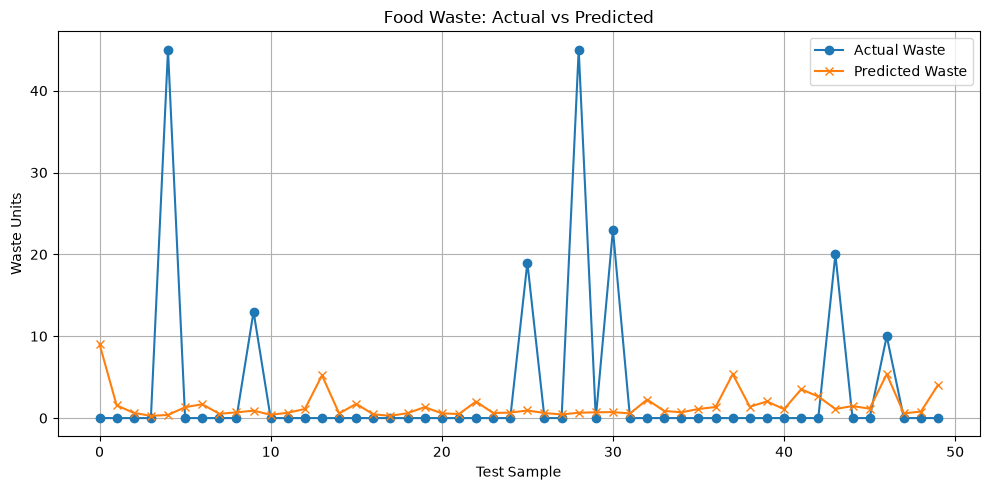

In [6]:
#Actual vs Predicted Graph


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    y_test.iloc[:50].to_numpy(),
    label="Actual Waste",
    marker="o"
)

plt.plot(
    waste_predictions[:50],
    label="Predicted Waste",
    marker="x"
)

plt.title("Food Waste: Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Waste Units")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
waste_results = test_df[
    ["target_date", "product_id", "category", "target_waste_units"]
].copy()

waste_results["predicted_waste_units"] = np.maximum(
    waste_predictions, 0
).round(2)

waste_results = waste_results.rename(
    columns={"target_waste_units": "actual_waste_units"}
)

display(waste_results.head(20))

,target_date,product_id,category,actual_waste_units,predicted_waste_units
143,2026-08-23,1001,Dairy,0.0,9.03
144,2026-08-24,1001,Dairy,0.0,1.56
145,2026-08-25,1001,Dairy,0.0,0.64
146,2026-08-26,1001,Dairy,0.0,0.27
147,2026-08-27,1001,Dairy,45.0,0.38
148,2026-08-28,1001,Dairy,0.0,1.33
149,2026-08-29,1001,Dairy,0.0,1.69
150,2026-08-30,1001,Dairy,0.0,0.52
151,2026-08-31,1001,Dairy,0.0,0.70
152,2026-09-01,1001,Dairy,13.0,0.91
